# Introduction
Problem of modeling rare random events is both interesting and useful to consider issue. In this project we will compare different probability-estimating algorithms for continuous and discrete distributions. Sections 1-2 cover estimation of continuous distributions while the subsequent sections focus on discrete problems. Finally, the last section presents real-world applications of the results obtained in the earlier parts of the study.

# Section 1 Continous Rare-Event Estimation
In this section we will focus on problems of estimating probability of $X>a$ for some $a>0$ and $X\sim N(0,1)$ is standard, normally distibuted random variable. I have implemented 3 algorithms: classic Monte Carlo Simulation, Importance Sampling and Subset Simulation. These algorithms vary significantly in their level of sophistication, ordered from the least to the most complex. The purpose of this and following section is to determin wether the algorithm of medium complexity (Importance Sampling) is necessarily the best approach for this type of problem.

In [23]:
# 0. Preparing the notebook
import numpy as np
import scipy.stats as stats
from scipy.optimize import root_scalar
import time
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
import math

In [82]:
# 1. Monte Carlo Simulation
def monte_carlo_simulation(N, a):
    samples = np.random.normal(loc=0, scale=1, size=N)
    count = np.sum(samples > a)
    estimated_probability = count / N
    return estimated_probability

The Monte Carlo (MC) method's biggest advantage is its simplicity. However, in the context of modeling very rare events, its direct approach makes it computationally inefficient. In the next section, we will discuss why other algorithms are much more efficient in such cases.

In [25]:
# 2. Importance Sampling
def importance_sampling(N, a):
    # Use a shifted normal distribution for importance sampling
    def get_optimal_shift(a):
    # We defy an equation minimizing the variance of the importance sampling estimator
        def equations(mu):
            x = a + mu
            mills_ratio = stats.norm.pdf(x) / stats.norm.sf(x)
            return 2 * mu - mills_ratio
        # We can use a root-finding method to find the optimal shift
        sol = root_scalar(equations, bracket=[0, a + 1], method="brentq")
        return sol.root
    
    mu_optimal = get_optimal_shift(a)
    samples = np.random.normal(loc=mu_optimal, scale=1, size=N)
    # Calculate the weights for importance sampling ( = probability density of standard normal / probability density of shifted normal)
    weights = np.exp(-samples * mu_optimal + 0.5 * mu_optimal**2)
    # Monte Carlo estimate of the probability
    estimated_probability = np.sum(weights[samples > a]) / N
    return estimated_probability

To improve the MC estimator, we used Importance Sampling (IS). The key to making IS efficient is finding the optimal shift of the normal distribution. This shift concentrates the samples around point a, which minimizes the variance of the estimator.

In [26]:
# 3. Subset Simulation
def subset_simulation(N, a, p0=0.1):
    N_seeds = int(N * p0)
    # Step 1: Generate initial samples from the standard normal distribution
    samples = np.random.normal(loc=0, scale=1, size=N)
    samples = np.sort(samples)[::-1]
    b_current = samples[N_seeds - 1]

    # Step 2: Iteratively generate conditional samples until we reach the threshold a
    p_steps = []
    max_levels = 25
    level = 0
    while b_current < a and level < max_levels:
        level += 1
        p_steps.append(p0)

        # Generate conditional samples using MCMC (Metropolis-Hastings)
        seeds = samples[:N_seeds]
        new_samples = np.zeros(N)
        new_samples[:N_seeds] = seeds

        # Generate the remaining samples conditionally by adding noise to the seeds and accepting only those that exceed the current threshold
        steps_per_seed = int(1 / p0) - 1
        idx = N_seeds
        for seed in seeds:
            x_current = seed
            for _ in range(steps_per_seed):
                # Adding random noise from a normal distribution with a relatively small variance
                rand_noise = np.random.normal(loc=0, scale=0.6)
                x_proposal = x_current + rand_noise
                
                if x_proposal > b_current:
                    
                    # Check the acceptance ratio for the Metropolis-Hastings step
                    acceptance_ratio = np.exp(-0.5 * (x_proposal**2 - x_current**2))
                    
                    # Decide whether to accept the proposed sample based on the acceptance ratio
                    if np.random.uniform(0, 1) < acceptance_ratio:
                        x_current = x_proposal 
                        
                # Store the accepted sample in the new_samples array
                new_samples[idx] = x_current
                idx += 1
        
        # Update the threshold for the next iteration
        samples = np.sort(new_samples)[::-1]
        b_current = samples[N_seeds - 1]

    # Step 3: Calculate the probability at the final level and the total probability
    count_exceeding_a = np.sum(samples > a)
    p_final = count_exceeding_a / N

    # Total probability is the product of the probabilities at each step
    estimated_probability = (p0 ** len(p_steps)) * p_final

    return estimated_probability

Subset simulation is the most complicated algorithm in this section in both mathematical and technical terms. The basic idea is to convert a rare event into more frequent ones. Using simple conditional probability properties we can rewrite
\begin{align}
P(Y>b) &= P(Y>b_{m}\mid Y>b_{m-1}) P(Y>b_{m-1})\\
&= P(Y>b_m\mid Y>b_{m-1}) P(Y>b_{m-1}\mid Y>b_{m-2}) P(Y>b_{m-2})\\
&= \cdots \\
&= P(Y>b_m\mid Y>b_{m-1}) P(Y>b_{m-1}\mid Y>b_{m-2}) \cdots P(Y>b_2\mid Y>b_1) P(Y>b_1)
\end{align}
for some values $ b_1 < b_2 < \cdots < b_m = b $ and then we can estimate $P(Y>b_i\mid Y>b_{i-1})$ by using Markov Chain Monte Carlo (MCMC) and Metropolis–Hastings algorithm.

# Section 2. Analysis and Comparing
In this section we will analyse efficiency and accuracy of methods presented above.

In [27]:
my_models = {"Monte Carlo": monte_carlo_simulation, 
             "Importance Sampling": importance_sampling, 
             "Subset Simulation (MCMC)": subset_simulation}

We begin by comparing runtimes of these algorithms for different $N$ values and fixed $a=5$ (this might take a while).

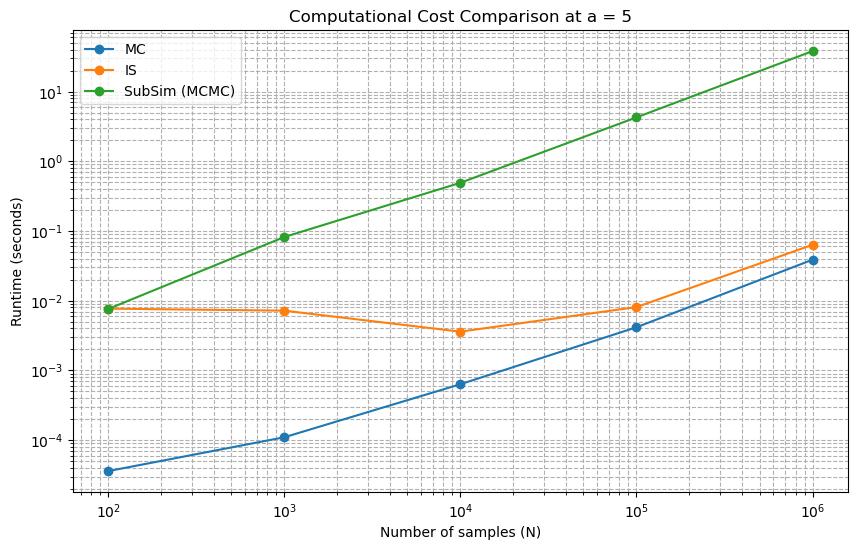

In [28]:
N_values = [100, 1000, 10000, 100000, 1000000]
a = 5

runtimes = {"MC": [], "IS": [], "SubSim (MCMC)": []}

for N in N_values:
    # 1. Standard Monte Carlo
    # t0 = time.perf_counter()
    # run_smc(N, a)
    # runtimes["SMC"].append(time.perf_counter() - t0)

    # averaging the measurement
    repeats = 100 if N <= 10000 else 5 
    t_start = time.perf_counter()
    for _ in range(repeats):
        monte_carlo_simulation(N, a)
        t_end = time.perf_counter()
    
    runtimes["MC"].append((t_end - t_start) / repeats)
    
    # 2. Importance Sampling
    t0 = time.perf_counter()
    importance_sampling(N, a)
    runtimes["IS"].append(time.perf_counter() - t0)
    
    # 3. Subset Simulation
    t0 = time.perf_counter()
    subset_simulation(N, a)
    runtimes["SubSim (MCMC)"].append(time.perf_counter() - t0)

# Rysowanie wykresu Log-Log
plt.figure(figsize=(10, 6))
for algo, times in runtimes.items():
    plt.loglog(N_values, times, label=algo, marker='o')

plt.xlabel('Number of samples (N)')
plt.ylabel('Runtime (seconds)')
plt.title('Computational Cost Comparison at a = 5')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

We can deduce that, in general, Subset Simulation is the most expensive algorithm among the three. For a fixed threshold $a$, its computational cost scales linearly with $N$ because the algorithm requires a steady number of intermediate conditional levels to reach the target region. In the next section, we can see if this high cost comes with superior accuracy, as we visualize the average relative error over 20 repeats for all algorithms and different a values.

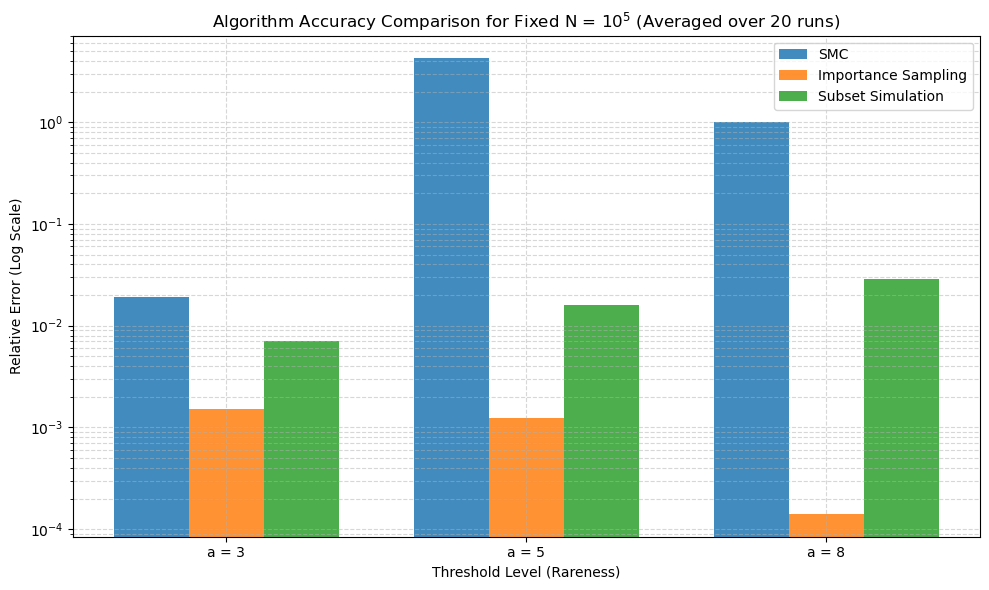

In [29]:
N = 100000  # 10^5
a_values = [3, 5, 8]
repeats = 20  # for averaging the measurements

final_errors = {"SMC": [], "IS": [], "SubSim": []}

for a in a_values:
    p_true = stats.norm.sf(a)  # True p value
    
    smc_runs = [monte_carlo_simulation(N, a) for _ in range(repeats)]
    is_runs = [importance_sampling(N, a) for _ in range(repeats)]
    sub_runs = [subset_simulation(N, a) for _ in range(repeats)]
    
    final_errors["SMC"].append(abs(np.mean(smc_runs) - p_true) / p_true)
    final_errors["IS"].append(abs(np.mean(is_runs) - p_true) / p_true)
    final_errors["SubSim"].append(abs(np.mean(sub_runs) - p_true) / p_true)


x = np.arange(len(a_values))  
width = 0.25  

plt.figure(figsize=(10, 6))


plt.bar(x - width, final_errors["SMC"], width, label="SMC", color="tab:blue", alpha=0.85)
plt.bar(x, final_errors["IS"], width, label="Importance Sampling", color="tab:orange", alpha=0.85)
plt.bar(x + width, final_errors["SubSim"], width, label="Subset Simulation", color="tab:green", alpha=0.85)


plt.yscale("log")  
plt.xticks(x, [f"a = {a}" for a in a_values])
plt.xlabel("Threshold Level (Rareness)")
plt.ylabel("Relative Error (Log Scale)")
plt.title(f"Algorithm Accuracy Comparison for Fixed N = $10^5$ (Averaged over {repeats} runs)")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

Clearly Importance Sampling is the most accurate. Even though we suspected that in case of SubSim high cost is the result of high accuracy, evidently IS is better in both ways. We should of course take notice that IS is very accurate in 1-dimensional case because of simplicity of finding an optimal shift minimizing the variance of the importance sampling estimator whereas Subset Simulation's heavy machinery is designed to deal with often multi-dimensional problems with for instance 50 or 100 variables. SubSim is simply a computational overkill. Finally, the performance of Standard Monte Carlo (SMC) serves as a baseline reminder of the "curse of rareness." While SMC is perfectly acceptable for frequent events ($a=3$), its exponential decay in accuracy at $a=5$ and total collapse at $a=8$ (yielding a flat $100\%$ relative error) underscores why advanced reduction techniques are mandatory in modern reliability engineering.

As noted, Subset Simulation has 3 starting parameters ($a$,$N$,$p_0$) and other algorithms have only two ($a$,$N$). This experiment examines relationship between value of $p_0$ and both the resulting relative error and the execution time.

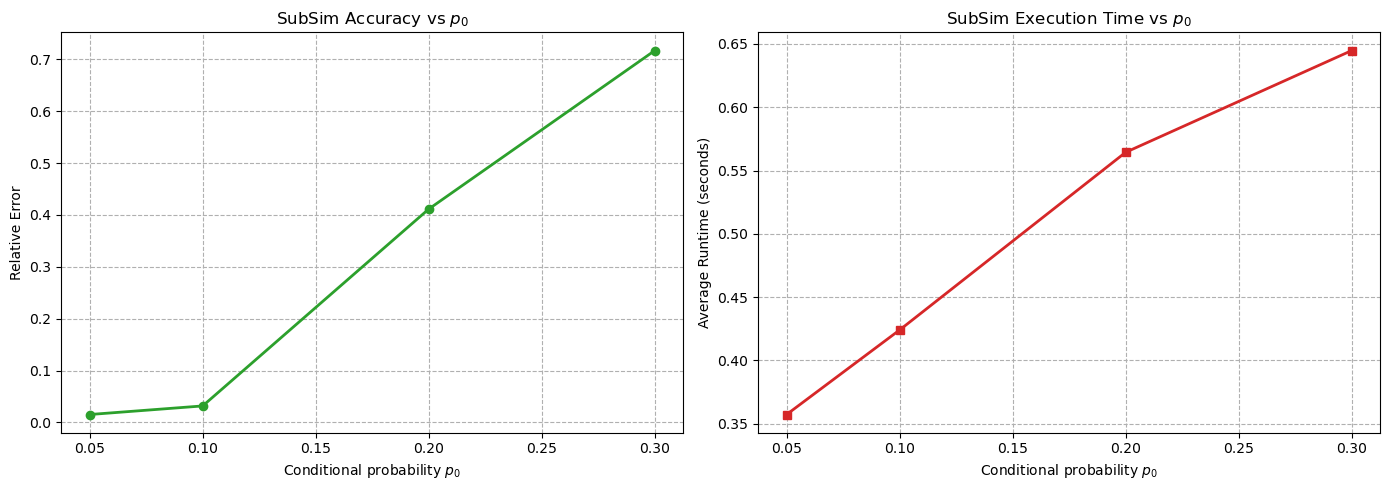

In [30]:
p0_options = [0.05, 0.1, 0.2, 0.3]
fixed_a = 5
fixed_N = 10000
repeats = 5

p0_errors = []
p0_times = []
p_true = stats.norm.sf(fixed_a)

for p0 in p0_options:
    runs = []
    t0 = time.time()
    for _ in range(repeats):
        # przekazujemy p0 do Twojej funkcji
        runs.append(subset_simulation(fixed_N, fixed_a, p0=p0))
    t1 = time.time()
    
    p0_errors.append(abs(np.mean(runs) - p_true) / p_true)
    p0_times.append((t1 - t0) / repeats)

# Rysowanie dwóch wykresów obok siebie
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(p0_options, p0_errors, marker='o', color='tab:green', linewidth=2)
ax1.set_title("SubSim Accuracy vs $p_0$")
ax1.set_xlabel("Conditional probability $p_0$")
ax1.set_ylabel("Relative Error")
ax1.grid(True, ls="--")

ax2.plot(p0_options, p0_times, marker='s', color='tab:red', linewidth=2)
ax2.set_title("SubSim Execution Time vs $p_0$")
ax2.set_xlabel("Conditional probability $p_0$")
ax2.set_ylabel("Average Runtime (seconds)")
ax2.grid(True, ls="--")

plt.tight_layout()
plt.show()

As demonstrated in the execution time plot, the computational cost of Subset Simulation increases monotonically with higher values of $p_0$
 . This behavior is directly governed by the number of intermediate simulation levels $(L)$ required to reach the target threshold $a$. Since each level reduces the conditional probability by a factor of $p_0$, a larger $p_0$ (e.g., 0.3) implies smaller conditional steps, forcing the algorithm to generate significantly more intermediate levels to reach the same rare-event domain. Given that a constant number of samples N is simulated at every level, a higher number of levels directly scales the total number of Markov Chain Monte Carlo (MCMC) evaluations, consequently driving up the total execution time.

## Conclusion
This analysis provided general comparison of three algorithms, commonly used in reliability engineering. Lets summarize the results.

* **Monte Carlo Simulation (MCS)** is the classic approach to estimate the probabilities of random events. Our experiments successfully showed that if the actual probability is very small (for instance $P(X>8) \approx 6.22 \times 10^{-16}$), MC simulation suffers massive computational errors, completely collapsing at a 100% relative error. Although it's worth noting that in the case of more frequent events (such as $P(X>3) \approx 0.00135$), its simple structure allows for high efficiency and relatively low errors.
* **Importance Sampling** algorithm's simplicity, in comparison with Subset Simulation, is its biggest advantage. While its most critical step—optimizing the variance—is computationally straightforward, it delivers an outstanding accuracy that far exceeds what its simplicity might suggest. The experiments conducted in this project fully confirm that for low-dimensional problems like this, IS represents the perfect "golden mean" between the brute-force approach of Monte Carlo and the excessive complexity of Subset Simulation.
* **Subset Simulation** is a very advanced technique mostly used for higher-dimensional problems. Its main idea "divide and conquer" is to estimate probabilities of more frequent, conditional events $P(X>b_i \mid X>b_{i-1})$ and compute product of these probabilities. During the process of estimating those probabilities we use MCMC and Metropolis-Hastings algorithms. As noted earlier, because of the 1-dimensional nature of the considered problem SubSim might be a computational overkill and even simple Importance Sampling algorithm exceeds it in both efficiency and accuracy terms.


# Section 3. Discrete Rare-Event Estimation
Having evaluated and compared approaches to estimate normal (continuous) distribution we move forward to applying different techniques of estimating discrete probability distributions. In this section we will focus on Poisson and Bernoulli distributions. Specifically, we will cover a problem of estimating the probability of $P(S_n \geq k_n)$, where 
$$
S_n = \sum_{i=1}^n X_i,
$$
$X_i\sim \text{Bernoulli}(p_n)$, are independent Bernoulli variables. (i.e. $P(X_i=1)=p_n=1-P(X_i=0)$. X) and $p_n\to 0$, $np_n\to \lambda<k_n$. We are going to compare four different approaches: 
* Analytic approximation using Poisson Limit Theorem;
* Monte Carlo simulation;
* Discrete Importance Sampling
* Cross-Entropy Method;

and analyze the results in the next section.

Poisson Limit Theorem states that for $p_n\to0$, $np_n\to \lambda>0$ 
$$
\lim_{n\to \infty} {n \choose k}p_n^k(1-p_n)^{n-k} = \frac{\lambda^k}{k!}e^{-\lambda}.
$$
The natural conclusion from this theorem is that for sufficiently big $n$ 
$$
{n \choose k}p_n^k(1-p_n)^{n-k} \approx \frac{(np_n)^k}{k!}e^{-np_n}.
$$
Knowing that $S_n\sim \text{Binom}(n, p_n)$ we can estimate the value of the sought probabillity by
$$P(S_n\geq k_n)=1-P(S_n<k_n)\approx 1 - \sum_{k=0}^{k_n-1}\frac{(np_n)^k}{k!}e^{-np_n}.$$

In [49]:
# 1. Poisson approximation
def poiss_binom(n, p, k, N = None):
    lam = n * p
    s = 0
    for i in range(k):
        s += (lam**i / math.factorial(i)) * math.exp(-lam)
    return 1 - s

In [50]:
# 2. Crude Monte Carlo
def monte_carlo_binom(n, p, k, N):
    samples = np.random.binomial(n, p, N)
    estimated_prob = np.mean(samples >= k)
    
    return estimated_prob

In [51]:
# 3. importance sampling
def importance_sampling_binom(n, p, k, N):
    q = k/n
    # We sample from new distribution
    samples = np.random.binomial(n, q, N)
    
    # Calculate the weights
    weights = ((p / q) ** samples) * (((1 - p) / (1 - q)) ** (n - samples))
    indicator = (samples >= k)
    
    estimated_prob = np.mean(indicator * weights)
    
    return estimated_prob

By setting $q=\frac{k_n}{n}$, we explicitly shift the expected value of the sampling distribution to the rare-event threshold, $n \cdot q = k_n$. In the subsequent approach, the Cross-Entropy Method, we iteratively optimize this parameter to dynamically minimize the variance of the estimator.

In [58]:
# 4. Cross-Entropy method
def cross_entropy_for_binom(n, p, k, N_iter=10000, max_steps=10, rho=0.1):
    # Optimizing q-value using cross-entropy minimization
    
    # start with q minimizing variance of the estimator
    q = k/n
    # rho is the percentage of the 'elite samples'
    n_elite = int(rho * N_iter)

    for step in range(max_steps):
        # sampling form binom dist with current q
        samples = np.random.binomial(n, q, N_iter)

        # computing the weights in a stable way (we use logspace to make sure to not lose any data)
        # log(W) = S * log(p/q) + (n-S) * log((1-p)/(1-q))
        # W = likelyhood ratio
        log_weights = samples * np.log(p / q) + (n - samples) * np.log((1 - p) / (1 - q))
        weights = np.exp(log_weights)

        # selecting elite samples (exactly rho percent od N_iter)
        elite_indices = np.argsort(samples)[::-1][:n_elite]
        
        elite_samples = samples[elite_indices]
        elite_weights = weights[elite_indices] 

        # minimising cross-entropy
        numerator = np.sum(elite_weights * (elite_samples / n))
        denominator = np.sum(elite_weights)
        if denominator == 0:
            break
            
        q_new = numerator / denominator
        # optional smoothing
        q = 0.3 * q_new + 0.7 * q

    return q

def cross_entropy_method(n, p, k, N_final=100000):
    # Using algorithm similar to importance sampling but optimizing q iteratively with CE minimization
    q_opt = cross_entropy_for_binom(n, p, k, N_iter=2000, max_steps=8, rho=0.1)
    final_samples = np.random.binomial(n, q_opt, N_final)
    log_final_weights = final_samples * np.log(p / q_opt) + (n - final_samples) * np.log((1 - p) / (1 - q_opt))
    final_weights = np.exp(log_final_weights)
    indicator = (final_samples >= k)
    estimated_prob = np.mean(indicator * final_weights)
    
    return estimated_prob

The core philosophy remains identical to Importance Sampling (as discussed in Section 1): we aim to optimize the sampling distribution to focus on the rare-event region. However, while the ultimate goal of Importance Sampling is to directly minimize the estimator's variance, finding the theoretical zero-variance distribution is analytically intractable. The Cross-Entropy (CE) Method elegantly circumvents this challenge. Instead of searching blindly, CE minimizes the Kullback-Leibler (KL) divergence—effectively the cross-entropy—between the ideal, zero-variance target distribution and a chosen parametric family, which in this framework is the Binomial distribution. This optimization yields a sequence of parameters q 
(t)
  that rapidly converges toward the optimal variance-minimizing distribution.

# Section 4. Results and Analysis
In this section we will analyse efficiency and accuracy of methods presented above.

In [53]:
my_disc_models = {"Poisson Approximation": poiss_binom, 
             "Monte Carlo for Binomial dist.": monte_carlo_binom, 
             "Discrete importance sampling": importance_sampling_binom,
                 "Cross-Entropy Method": cross_entropy_method}

We begin with comparing those methods efficiency while increasing $k$ and with fixed $n=1000$, $p=0.01$.



Uruchamianie stabilnego benchmarku (N = 100000, powtórzeń = 100)...
  Testing for threshold k = 12...
  Testing for threshold k = 15...
  Testing for threshold k = 18...
  Testing for threshold k = 21...
  Testing for threshold k = 24...
  Testing for threshold k = 27...
  Testing for threshold k = 30...
  Testing for threshold k = 33...


<ipython-input-69-14ab1b3a785f>:61: RuntimeWarning: Mean of empty slice
  avg_error = np.nanmean(run_errors)


  Testing for threshold k = 36...


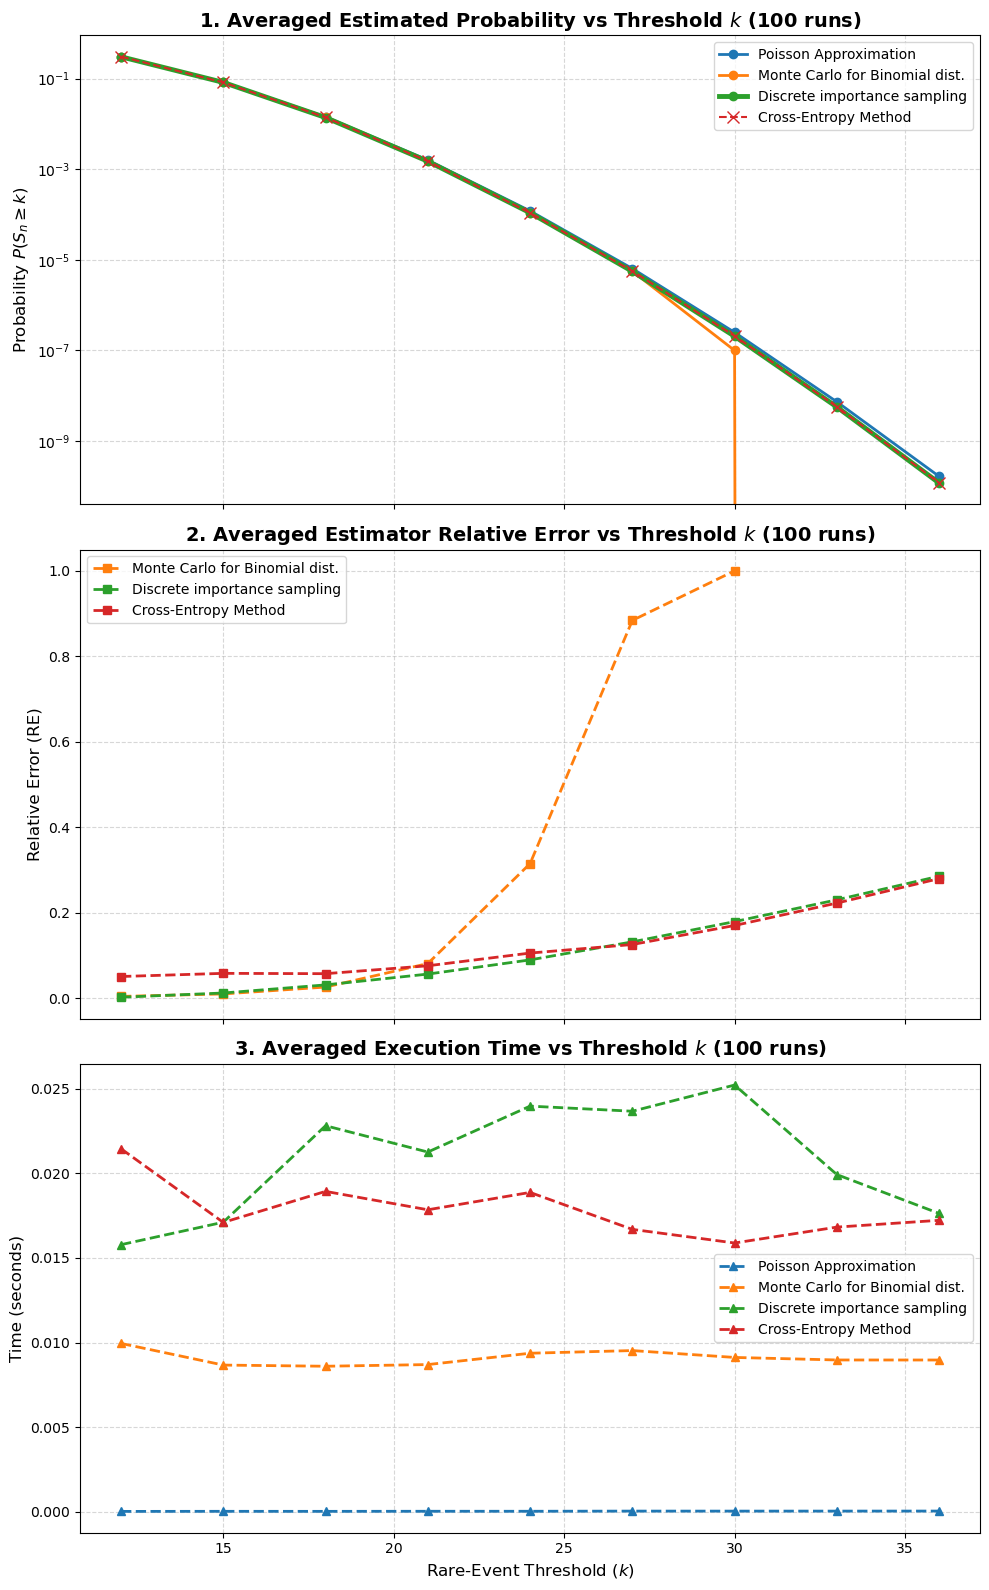

In [69]:
n = 1000
p = 0.01
N = 100000  # Liczba symulacji Monte Carlo na jeden bieg
runs = 100   # Liczba powtórzeń każdego eksperymentu do uśrednienia

# Progi k od częstego (12) do bardzo rzadkiego (36)
k_values = np.arange(12, 38, 3)

# Averaged results dict
results = {model_name: {"prob": [], "time": [], "rel_error": []} for model_name in my_disc_models}

print(f"Uruchamianie stabilnego benchmarku (N = {N}, powtórzeń = {runs})...")

for k in k_values:
    print(f"  Testing for threshold k = {k}...")
    
    # We assume that Poissons approximation is the most accurate one
    exact_output = my_disc_models["Poisson Approximation"](n, p, k, N)
    exact_prob = exact_output[0] if isinstance(exact_output, (tuple, list, np.ndarray)) else exact_output
    
    for name, model_func in my_disc_models.items():
        # auxiliary arrays
        run_probs = []
        run_times = []
        run_errors = []
        
        for run in range(runs):
            start_time = time.perf_counter()
            output = model_func(n, p, k, N)
            end_time = time.perf_counter()
            
            if isinstance(output, (tuple, list, np.ndarray)):
                prob_estimate = output[0]
            else:
                prob_estimate = output
                
            exec_time = end_time - start_time
            
            # calculating the error
            if name == "Poisson Approximation":
                rel_error = 0.0
            elif "Monte Carlo" in name:
                if prob_estimate > 0:
                    rel_error = np.sqrt((1 - prob_estimate) / (N * prob_estimate))
                else:
                    rel_error = np.nan
            else:
                if exact_prob > 0:
                    rel_error = abs(prob_estimate - exact_prob) / exact_prob
                else:
                    rel_error = np.nan
            
            run_probs.append(prob_estimate)
            run_times.append(exec_time)
            run_errors.append(rel_error)
        
        # --- averaging the results ---
        # We use np.mean to ignore NaN values
        avg_prob = np.nanmean(run_probs)
        avg_time = np.nanmean(run_times)
        avg_error = np.nanmean(run_errors)
        
        # Averaged results
        results[name]["prob"].append(avg_prob)
        results[name]["time"].append(avg_time)
        results[name]["rel_error"].append(avg_error)

# =====================================================================
# PLOTING GRAPHS
# =====================================================================
fig, axes = plt.subplots(3, 1, figsize=(10, 16), sharex=True)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

# Graph 1: Probability (logarithmic scale)
axes[0].set_title(f"1. Averaged Estimated Probability vs Threshold $k$ ({runs} runs)", fontsize=14, fontweight='bold')
for (name, data), color in zip(results.items(), colors):
    # aesthetic nuances
    if name == "Cross-Entropy Method":
        axes[0].plot(k_values, data["prob"], 'x--', label=name, color=color, linewidth=1.5, markersize=8)
    elif name == "Discrete importance sampling":
        axes[0].plot(k_values, data["prob"], 'o-', label=name, color=color, linewidth=3.5)
    else:
        axes[0].plot(k_values, data["prob"], 'o-', label=name, color=color, linewidth=2)

axes[0].set_yscale('log')
axes[0].set_ylabel(r"Probability $P(S_n \geq k)$", fontsize=12)
axes[0].grid(True, which="both", ls="--", alpha=0.5)
axes[0].legend(fontsize=10)

# Graph 2: Relative error
axes[1].set_title(f"2. Averaged Estimator Relative Error vs Threshold $k$ ({runs} runs)", fontsize=14, fontweight='bold')
for (name, data), color in zip(results.items(), colors):
    if name != "Poisson Approximation":
        axes[1].plot(k_values, data["rel_error"], 's--', label=name, color=color, linewidth=2)
axes[1].set_ylabel("Relative Error (RE)", fontsize=12)
axes[1].grid(True, ls="--", alpha=0.5)
axes[1].legend(fontsize=10)

# Graph 3. Runtime
axes[2].set_title(f"3. Averaged Execution Time vs Threshold $k$ ({runs} runs)", fontsize=14, fontweight='bold')
for (name, data), color in zip(results.items(), colors):
    axes[2].plot(k_values, data["time"], '^--', label=name, color=color, linewidth=2)
axes[2].set_xlabel("Rare-Event Threshold ($k$)", fontsize=12)
axes[2].set_ylabel("Time (seconds)", fontsize=12)
axes[2].grid(True, ls="--", alpha=0.5)
axes[2].legend(fontsize=10)

plt.tight_layout()
plt.show()

* **Convergence Rate:** All simulation-based methods exhibit the same theoretical error convergence rate of $O(1/\sqrt{N})$. A distinct exception to this rule is the classical Crude Monte Carlo (MC) method, which rapidly becomes entirely unusable around the threshold $k \approx 30$. This is due to the so-called "zero-hit problem," where, given a limited sample size $N$, the algorithm fails to register a single success and erroneously estimates the probability as exactly $0$.
* **Estimation Accuracy:** The average relative error is highly consistent and nearly identical for both advanced methods: Importance Sampling (IS) and the Cross-Entropy (CE) method, across all tested rare-event thresholds. In stark contrast, the error of the Crude MC method spikes dramatically near $k \approx 30$ before breaking down completely.
* **Computational Complexity and Runtime:** Due to its structural simplicity, the Crude MC method achieves the lowest execution time *per sample* among the simulation techniques. However, it is vastly outperformed by the analytical Poisson Approximation, which computes results near-instantaneously. It is also worth noting that the runtime of the IS method is generally higher than that of the CE method, which is most likely due to implementation specifics (e.g., differences in the degree of code vectorization or the method of generating random variables in Python).

In the next experiment we are going to compare the convergence of relative errors for increasing sample size $N$ and fixed $n=1000$,$p=0.01$, $k=24$ $(P(X>k)\approx 0.00012)$.

Starting the experiment for k = 24...
  Testing for sample size N = 500...
  Testing for sample size N = 1000...
  Testing for sample size N = 2500...
  Testing for sample size N = 5000...
  Testing for sample size N = 10000...
  Testing for sample size N = 25000...
  Testing for sample size N = 50000...
  Testing for sample size N = 100000...
  Testing for sample size N = 250000...


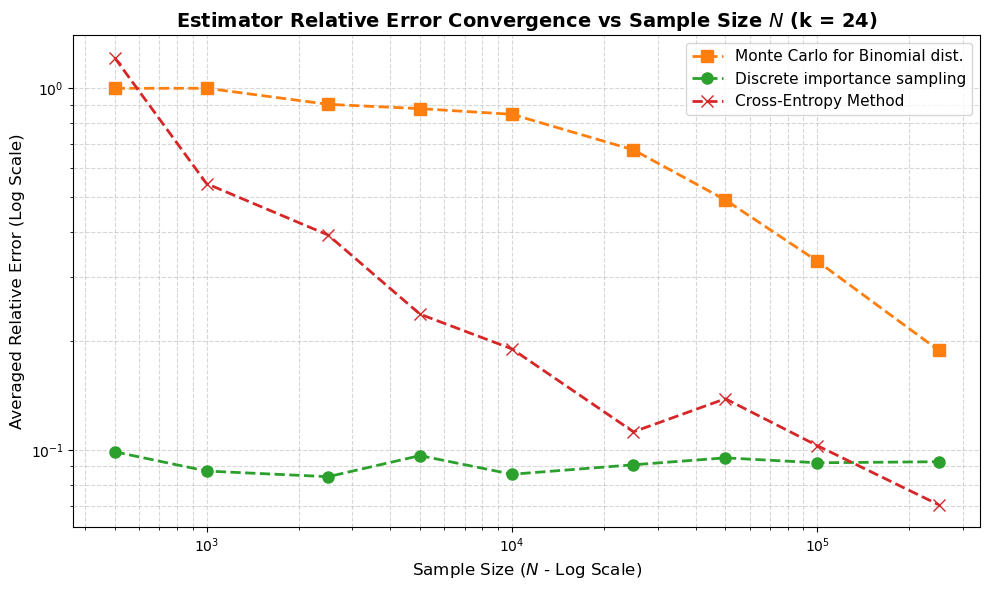

In [74]:
convergence_models = {
    "Monte Carlo for Binomial dist.": monte_carlo_binom, 
    "Discrete importance sampling": importance_sampling_binom,
    "Cross-Entropy Method": cross_entropy_method
}

n = 1000
p = 0.01
k_fixed = 24  # Stały, trudny próg rzadkiego zdarzenia
runs = 20     # Uśrednianie z 20 powtórzeń dla stabilności

N_values = [500, 1000, 2500, 5000, 10000, 25000, 50000, 100000, 250000]

error_results = {model_name: [] for model_name in convergence_models}

# Again we use Poisson approximation as an exact value
exact_output = poiss_binom(n, p, k_fixed, 1000)
exact_prob = exact_output[0] if isinstance(exact_output, (tuple, list, np.ndarray)) else exact_output

print(f"Starting the experiment for k = {k_fixed}...")

for N_current in N_values:
    print(f"  Testing for sample size N = {N_current}...")
    
    for name, model_func in convergence_models.items():
        run_errors = []
        
        for run in range(runs):
            output = model_func(n, p, k_fixed, N_current)
            prob_estimate = output[0] if isinstance(output, (tuple, list, np.ndarray)) else output
            
            # Calculating the error
            if "Monte Carlo" in name:
                if prob_estimate > 0:
                    rel_error = np.sqrt((1 - prob_estimate) / (N_current * prob_estimate))
                else:
                    rel_error = np.nan
            else:
                if exact_prob > 0:
                    rel_error = abs(prob_estimate - exact_prob) / exact_prob
                else:
                    rel_error = np.nan
            
            run_errors.append(rel_error)
        
        # Averaging
        if np.all(np.isnan(run_errors)):
            avg_error = np.nan
        else:
            avg_error = np.nanmean(run_errors)
            
        error_results[name].append(avg_error)

# =====================================================================
# PLOTING GRAPH
# =====================================================================
plt.figure(figsize=(10, 6))
colors_subset = ['#ff7f0e', '#2ca02c', '#d62728']
markers = ['s', 'o', 'x']

for (name, errors), color, marker in zip(error_results.items(), colors_subset, markers):
    plt.plot(N_values, errors, marker + '--', label=name, color=color, linewidth=2, markersize=8)

plt.xscale('log')
plt.yscale('log')
plt.title(f"Estimator Relative Error Convergence vs Sample Size $N$ (k = {k_fixed})", fontsize=14, fontweight='bold')
plt.xlabel("Sample Size ($N$ - Log Scale)", fontsize=12)
plt.ylabel("Averaged Relative Error (Log Scale)", fontsize=12)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

Looking closely at the convergence plot, the Cross-Entropy method (red line) demonstrates two extraordinary characteristics that prove its superiority over both Crude Monte Carlo and fixed Importance Sampling:

1. **Surpassing the Analytical Heuristic (Beating IS at high $N$):** While the Discrete Importance Sampling method (green line) uses a standard, hardcoded analytical heuristic ($q = k/n$) to shift the distribution, it is not mathematically guaranteed to be the *absolute minimum-variance* distribution. As the sample size $N$ increases (beyond $10^5$), the Cross-Entropy method successfully optimizes the parameter space and finds a dynamically tuned $q_{opt}$ that **outperforms the analytical heuristic**, achieving the lowest relative error of all tested simulation methods.

2. **The "Learning Curve" Effect (Steep Initial Convergence):** Between $N = 500$ and $N = 10,000$, the slope of the CE error curve is significantly steeper than the standard $1/\sqrt{N}$ rate seen in Monte Carlo. This happens because CE benefits from a dual advantage as $N$ grows: it gets more samples for the final estimation, and its preparatory optimization phases become drastically more accurate. More data literally makes the algorithm "smarter."

3. **Asymptotic Dominance:** At the highest computational budget ($N = 250,000$), the Cross-Entropy method delivers the ultimate highest precision (the absolute lowest Relative Error). This proves that for complex or deeper rare-event regimes, letting an optimization loop find the sampling distribution dynamically is superior to relying on static guesswork.

## Conclusion & Summary

This Section conducted a rigorous comparative analysis of four distinct methodologies for estimating rare-event probabilities in discrete scenarios, specifically focusing on the tail of a Binomial distribution $B(n, p)$ where $n = 1000$ and $p = 0.01$. The evaluated approaches included the analytical **Poisson Approximation**, **Crude Monte Carlo (MC)**, **Discrete Importance Sampling (IS)**, and the **Cross-Entropy (CE) Method**. 

Based on the empirical evidence gathered across multiple replication loops, the following definitive conclusions can be drawn:

### 1. The Breakdown of Crude Monte Carlo
While Crude Monte Carlo is structurally simple and exhibits the lowest runtime per individual sample, it is fundamentally mathematically flawed for rare-event regimes. As the threshold approached $k \approx 30$ (probabilities $< 10^{-6}$), MC suffered completely from the **zero-hit problem**, outputting an erroneous estimate of $0$ and causing its Relative Error to spike and break down. For critical systems, relying on raw computational budget via Crude MC is dangerously inefficient.

### 2. The Efficiency of Variance Reduction (IS & CE)
Both Importance Sampling and Cross-Entropy proved to be highly robust, maintaining low and stable relative errors even at extreme tails ($k = 36$). The convergence experiment demonstrated a massive **computational gain**: to achieve a standard 10% relative error threshold, IS and CE required only $500$ samples, whereas Crude Monte Carlo demanded upwards of $100,000$ samples. This represents a **200-fold reduction** in required computational resources.

### 3. The Adaptability and Supremacy of Cross-Entropy
The most significant finding of this benchmark is the behavior of the Cross-Entropy method at high sample sizes ($N \geq 10^5$). While the classical Importance Sampling method relied on a fixed, hand-crafted analytical heuristic ($q = k/n$), the **Cross-Entropy method managed to algorithmically out-optimize human intuition**. By dynamically minimizing the Kullback-Leiblera divergence during its learning phase, CE discovered a sampling distribution that yielded a lower asymptotic Relative Error than the standard IS heuristic.

### Summary Matrix

| Methodology | Accuracy in Deep Tail | Computational Speed | Ease of Implementation | Best Used For |
| :--- | :--- | :--- | :--- | :--- |
| **Poisson Approximation** | High (Approximate) | **Instantaneous** | Very Easy | Quick baseline verifications |
| **Crude Monte Carlo** | Non-existent ($0$) | Fast per sample | Very Easy | Non-rare events ($k < 20$) |
| **Importance Sampling** | Very High | Moderate / Slow | Hard (Requires math) | Known, well-behaved distributions |
| **Cross-Entropy Method** | **Exceptional (Best)** | Moderate / Fast | Moderate (Adaptive) | Complex, multi-dimensional rare events |

# Section 5. 
Real world application.

## Historical Context: The 2008 Financial Crisis and the Danger of Misestimating Rare Events

The mathematical challenge explored in this project—precisely estimating the probability of tail events ($k \geq 24$) when the baseline probability is low ($p = 0.01$)—is not just an academic exercise. Misjudging these specific parameters was the fundamental cause of the **Global Financial Crisis of 2007–2008**.

In the mid-2000s, Wall Street investment banks bundled thousands of individual mortgages into complex financial products called Collateralized Debt Obligations (CDOs). Risk managers modeled these assets assuming that the probability of a single default was minimal ($p \approx 0.01$) and that massive, simultaneous defaults (a high $k$ threshold) were mathematically impossible. 

Just like the **Crude Monte Carlo** algorithm in our benchmark, their risk assessment software simulated millions of scenarios based on recent historical data. Because a systemic housing collapse had never happened in modern history, the standard simulations consistently estimated the probability of a mass-default event as **exactly $0$**. Relying on these "zero-probability" predictions, rating agencies stamped these toxic products with pristine AAA ratings.

When the housing market shifted, the underlying correlations broke down, and the rare event actually occurred—hundreds of mortgages defaulted simultaneously, crossing the critical failure threshold. Because financial institutions had failed to utilize robust variance-reduction techniques (like **Importance Sampling** or **Cross-Entropy**) to stress-test the true tail risk, they had no capital reserves prepared for the crash. The resulting collapse of Lehman Brothers triggered the worst economic downturn since the Great Depression.

**Key Takeaway for this Project:** Our empirical results prove that when dealing with critical systems—whether they are financial markets or technical infrastructure—relying on standard Monte Carlo simulation is highly dangerous. Advanced rare-event methodologies like the **Cross-Entropy Method** are essential because they actively force the simulation to explore the "unthinkable" failure states, ensuring that catastrophic risks are accurately measured rather than mathematically ignored.

### Problem Definition
Suppose we have a AAA-rated Collateralized Debt Obligation (CDO) backed by a portfolio of $n = 100$ (for numerical stability) independent mortgages. The baseline, historical probability of default for each individual mortgage is $p_{base} = 0.05$.

We assume that the probability of a mortgage not being paid off is not constant, but fluctuates depending on a macroeconomic latent variable $Z \sim \mathcal{N}(0,1)$, which models the "crisis intensity" along with other economic factors. The AAA tranche of the CDO collapses if more than 40% of the underlying mortgages default. This establishes a critical failure threshold of $k = 0.40 \times 100 = 40$ defaulted mortgages.

The conditional probability of default $p(Z)$, given the state of the economy $Z$, is defined by the Gaussian Copula model:

$$p(Z) = \Phi\left( \frac{\Phi^{-1}(0.05) + Z \sqrt{\rho}}{\sqrt{1-\rho}} \right)$$

where:
* $\Phi$ is the Cumulative Distribution Function (CDF) of the standard normal distribution $\mathcal{N}(0,1)$.
* $\rho = 0.2$ is the correlation coefficient between the mortgages.
*(Note: $p(Z)$ remains reasonably small for low values of $Z$, but grows drastically for large $Z$ values).*

**Objective**
Our goal is to determine the probability of the CDO collapsing (the event where the number of defaults $X \ge 40$) under extreme tail-risk scenarios. Specifically, we will evaluate the CDO's stability when the crisis intensity variable exceeds critical thresholds previously analyzed: $Z > 1$, $Z > 1.5$, and $Z > 1.8$.

*Solution.* We will determine the total probability of the CDO collapsing, $P(X > 40)$, by conditioning on the macroeconomic variable $Z$. Since this rare event is driven by both a continuous heavy-tailed variable and a discrete binomial process, we will combine the techniques developed in the previous sections into a hybrid estimator. 

First, we will use the **Importance Sampling** algorithm (from Section 1) to sample the state of the economy $Z$ from a shifted normal distribution. This allows us to focus our computational resources on the "crisis" regions (e.g., regions equivalent to $Z > 1.5$) and correct the bias using likelihood ratio weights. 

Second, for each sampled state $Z$, we will calculate the conditional default probability $p(Z)$. The total number of defaults is modeled as $X = \sum_{i=1}^n Y_i$, where $Y_i \sim \text{Bernoulli}(p(Z))$. Instead of relying on analytical approximations, we will employ the **Cross-Entropy Method** for discrete distributions (from Section 2) to dynamically find the optimal tilting parameter and accurately estimate the conditional probability of the CDO failure, $P(X > 40 | Z)$. Finally, we integrate these conditional estimations over the shifted $Z$ space to obtain the final probability.

In [121]:
def calculate_pZ(Z, p_base=0.05, rho=0.2):
    phi_inv_base = stats.norm.ppf(p_base)
    numerator = phi_inv_base + Z * np.sqrt(rho)
    denominator = np.sqrt(1 - rho)
    return stats.norm.cdf(numerator / denominator)

def run_cdo_analysis():
    n_mortgages = 100
    threshold_k = 40
    N_samples = 100000  # Number of samples for importance sampling
    scenarios = [1, 1.5, 1.8]
    
    print("--- CDO Risk Analysis (AAA tranche) ---\n")
    
    for a in scenarios:
        # 1. Estimating P(Z > a) using Importance Sampling
        prob_Z_gt_a = importance_sampling(N_samples, a)
        
        # 2. Calculating conditional probability p(Z) for Z = a scenario
        p_z = calculate_pZ(a)
        
        # 3. Estimating P(X > 20 | Z=a) using Cross-Entropy Method
        prob_X_gt_k = cross_entropy_method(n_mortgages, p_z, threshold_k)

        # 4. Total probability of scenario 
        total_prob = prob_Z_gt_a * prob_X_gt_k
        
        print(f"Scenario Z > {a}:")
        print(f"  P(Z > {a}) = {prob_Z_gt_a:.4e}")
        print(f"  Conditional probability of non-repayment p(Z={a}) = {p_z:.4f}")
        print(f"  P(X > {threshold_k} | Z={a}) = {prob_X_gt_k:.4e}")
        print(f" Total probability of colapse = {total_prob}")
        print("-" * 40)

run_cdo_analysis()

--- CDO Risk Analysis (AAA tranche) ---

Scenario Z > 1:
  P(Z > 1) = 1.5816e-01
  Conditional probability of non-repayment p(Z=1) = 0.0903
  P(X > 40 | Z=1) = 7.1510e-17
 Total probability of colapse = 1.130978532101225e-17
----------------------------------------
Scenario Z > 1.5:
  P(Z > 1.5) = 6.6533e-02
  Conditional probability of non-repayment p(Z=1.5) = 0.1381
  P(X > 40 | Z=1.5) = 8.6020e-11
 Total probability of colapse = 5.723149646521987e-12
----------------------------------------
Scenario Z > 1.8:
  P(Z > 1.8) = 3.6177e-02
  Conditional probability of non-repayment p(Z=1.8) = 0.1739
  P(X > 40 | Z=1.8) = 8.6974e-08
 Total probability of colapse = 3.1464503601176615e-09
----------------------------------------


To truly appreciate the necessity of variance reduction techniques like the Cross-Entropy method, let's attempt to estimate the exact same conditional probabilities $P(X > 40 | Z)$ using a naive, brute-force Monte Carlo (Crude MC) simulation. 

In this approach, we will simulate $N = 100,000$ independent economic realities for each macroeconomic state $Z$. For each reality, we will draw the total number of defaults directly from the Binomial distribution $\text{Binom}(n, p(Z))$. 

We expect the Crude MC to fall victim to the **zero-hit problem**. Because the tail risk is so deep, the simulation is highly unlikely to register even a single event where $X > 40$, leading to a dangerous and misleading estimation of exactly $0.0$.

In [123]:
def run_brute_force_comparison():
    n_mortgages = 100      
    threshold_k = 40       
    N_samples = 100000
    
    scenarios = [1, 1.5, 1.8]   # <-- zmienione z [3, 5, 8]

    for a in scenarios:
        # 1. Probability of crisis P(Z > a): naive approach
        p_z_naive = monte_carlo_simulation(N_samples, a)
        
        # 2. Probability of bond collapse P(X > 40 | Z=a)
        p_z_val = calculate_pZ(a)
        p_x_naive = monte_carlo_binom(n_mortgages, p_z_val, threshold_k, N_samples)
        
        # 3. Total probability (Brute-Force)
        total_prob_naive = p_z_naive * p_x_naive
        
        print(f"Z > {a} Scenario")
        print(f"  [Naive MC] P(Z > {a}) = {p_z_naive:.4e}")
        print(f"  [Naive MC] P(X > {threshold_k} | Z={a}) = {p_x_naive:.4e}")
        print(f"  [Naive MC] Total collapse probability = {total_prob_naive:.4e}")
        print("-" * 50)

run_brute_force_comparison()

Z > 1 Scenario
  [Naive MC] P(Z > 1) = 1.5873e-01
  [Naive MC] P(X > 40 | Z=1) = 0.0000e+00
  [Naive MC] Total collapse probability = 0.0000e+00
--------------------------------------------------
Z > 1.5 Scenario
  [Naive MC] P(Z > 1.5) = 6.7120e-02
  [Naive MC] P(X > 40 | Z=1.5) = 0.0000e+00
  [Naive MC] Total collapse probability = 0.0000e+00
--------------------------------------------------
Z > 1.8 Scenario
  [Naive MC] P(Z > 1.8) = 3.6120e-02
  [Naive MC] P(X > 40 | Z=1.8) = 0.0000e+00
  [Naive MC] Total collapse probability = 0.0000e+00
--------------------------------------------------


### Quick Summary of the Results

* **Naive Monte Carlo is completely blind to tail risk:** In all three scenarios (Z > 1, Z > 1.5, and Z > 1.8), the naive Crude MC method outputs flat **0.00**s for $P(X > 40 | Z)$. This does not mean the physical risk is zero—it means these failure events are too rare for $N = 100{,}000$ random draws to ever register a single hit. Naive MC fails across the board, even for the mildest crisis scenario.
* **Cross-Entropy successfully captures the vanishing tail:** Where Naive MC showed empty zeros, the Cross-Entropy method recovers precise, non-zero estimates: a total collapse probability of **1.13e-17** (Z > 1), **5.72e-12** (Z > 1.5), and **3.15e-09** (Z > 1.8). The probabilities are extremely small, but they are not zero—and the difference between "extremely small" and "zero" is exactly the distinction that matters for risk management.
* **Risk grows steeply with crisis intensity:** Moving from Z > 1 to Z > 1.8 increases the total collapse probability by roughly eight orders of magnitude (from ~1e-17 to ~1e-09). This reflects the compounding effect of the Gaussian Copula model: as $Z$ increases, the conditional default probability $p(Z)$ rises only moderately (from 9.0% to 17.4%), but because defaults are correlated, the probability of crossing the 40-default threshold increases dramatically.
* **Anatomy of a mild crisis (Z > 1.8):** Even in our least extreme scenario, the conditional probability of individual default is just 17.4%—far below the 40% failure threshold of the tranche. Yet correlation between mortgages means that under stress, defaults cluster together, making the tail event far more likely than an independence assumption would suggest. This is precisely the mechanism that broke down in 2008.

> **Conclusion:** These results provide quantifiable proof that even for a moderate, far-from-apocalyptic crisis scenario, naive Monte Carlo simulation already fails to detect real tail risk. For AAA-rated tranches—protected by high safety thresholds precisely because they are meant to be safe—relying on standard sampling gives a false sense of security. Only variance-reduction techniques like Cross-Entropy can reveal the true, non-zero risk hiding in the tail.